# Sea surface temperature projections

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid. Every model's annual series is averaged over each EEZ and ocean region (cosine-of-latitude weights) and expressed as the change relative to its own 2015–2035 mean. For each indicator:

* **Trend map** — linear trend over 2015–2100 of the multi-model median change in each EEZ, one panel per scenario.
* **Warming-level map** — multi-model median change in each EEZ in the year `map_scenario` first reaches each global warming level.
* **Ocean-region box plots** — spread across models at each warming level for the four ocean regions, one figure per region.

```{glue:figure} tos_fig
:scale: 60%
:align: center
```

**Figure. Change in sea surface temperature relative to 2015–2035 in each Pacific EEZ at the global warming levels** (multi-model median, `map_scenario`).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels use `map_scenario`; box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Sea surface temperature

Annual mean sea surface temperature (°C) from monthly SST.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,35,0.168,-0.083,0.284,-0.181,0.443
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,35,0.125,-0.036,0.336,-0.121,0.400
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,33,1.187,0.741,1.691,0.326,1.867
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,35,0.022,-0.173,0.183,-0.441,0.302
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,35,0.395,0.184,0.593,-0.043,0.699
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,35,0.723,0.453,1.101,0.162,1.462


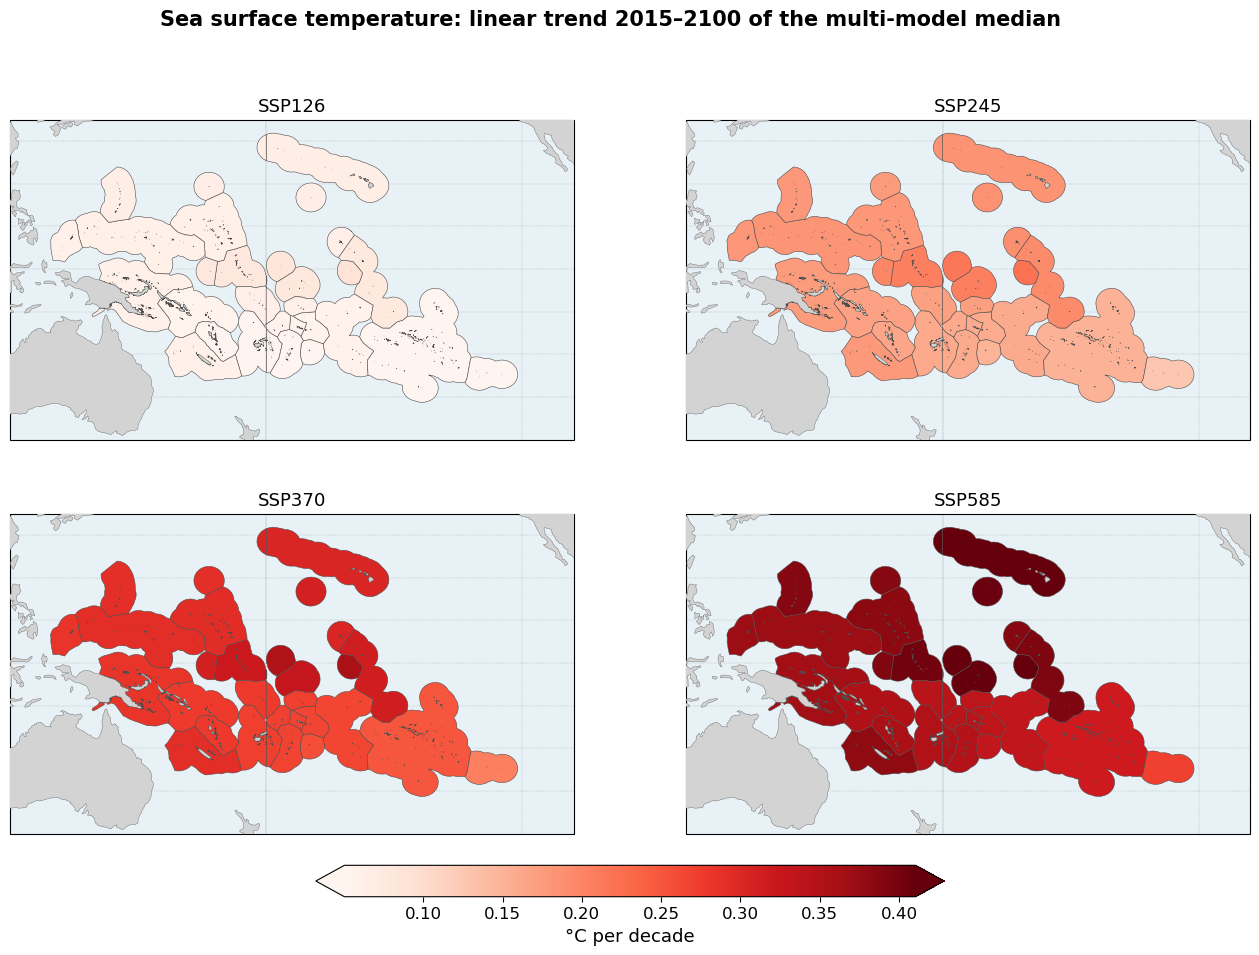

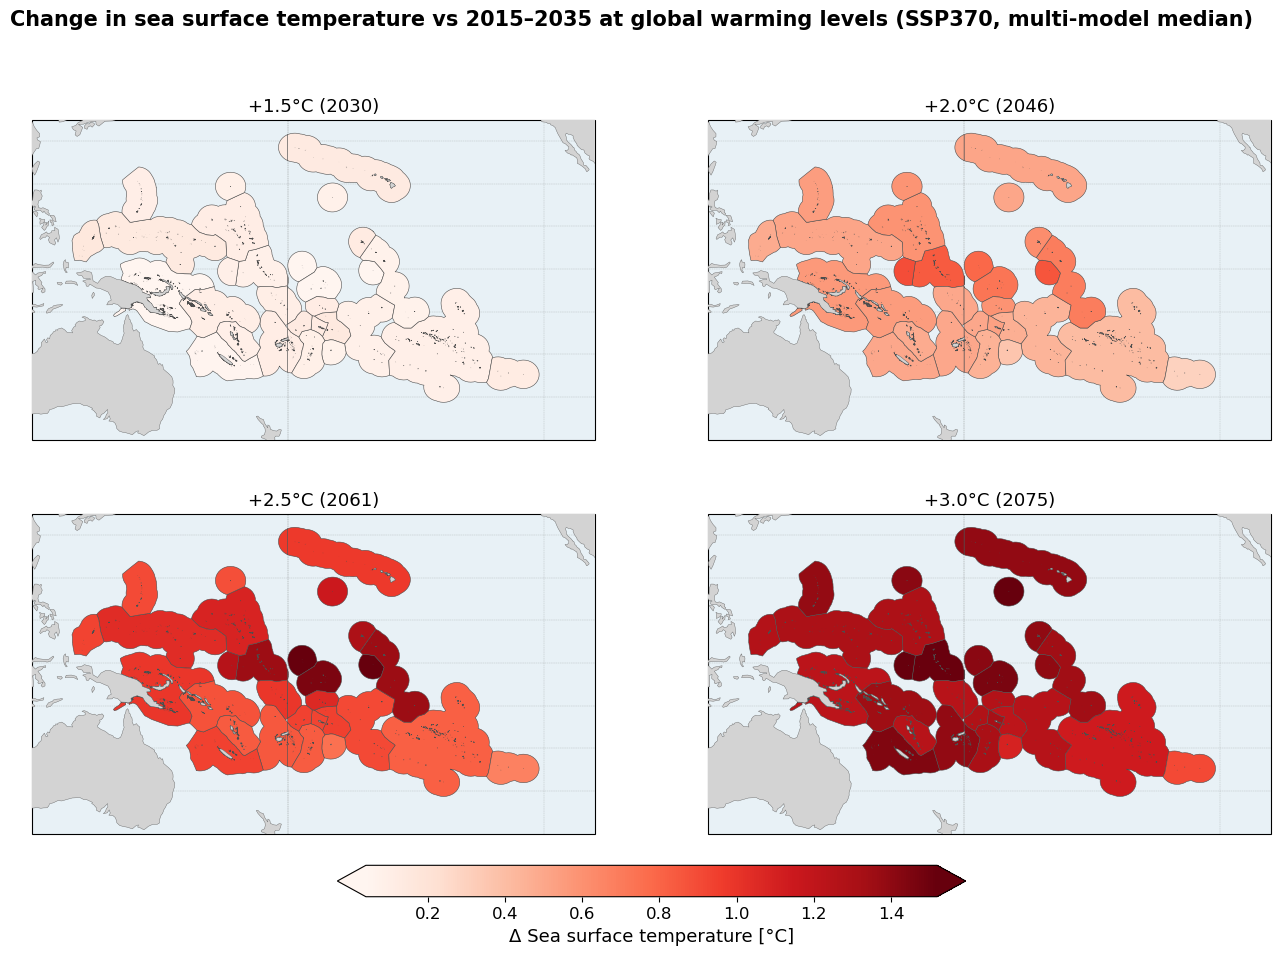

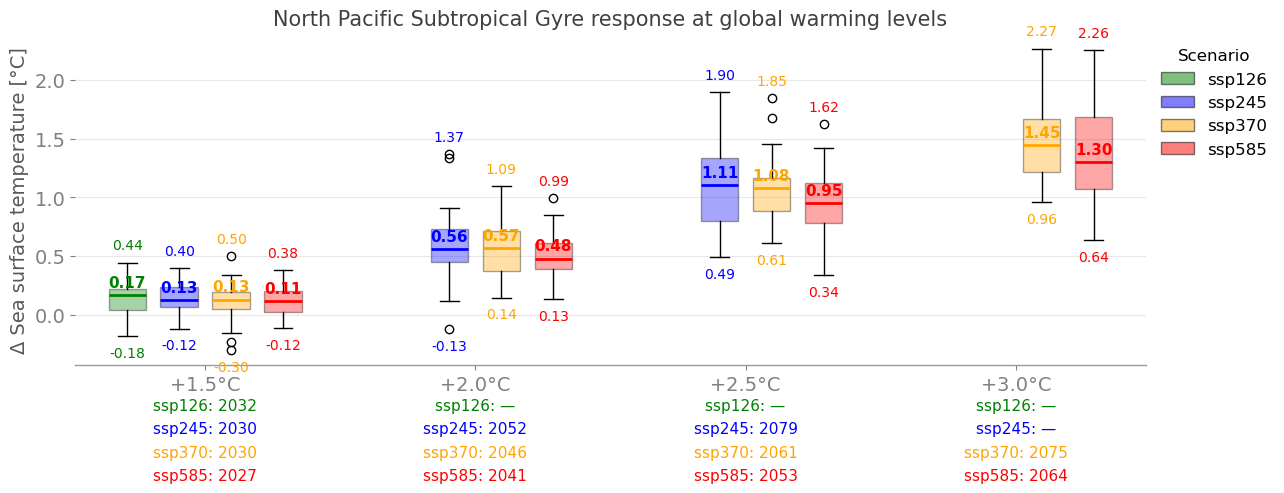

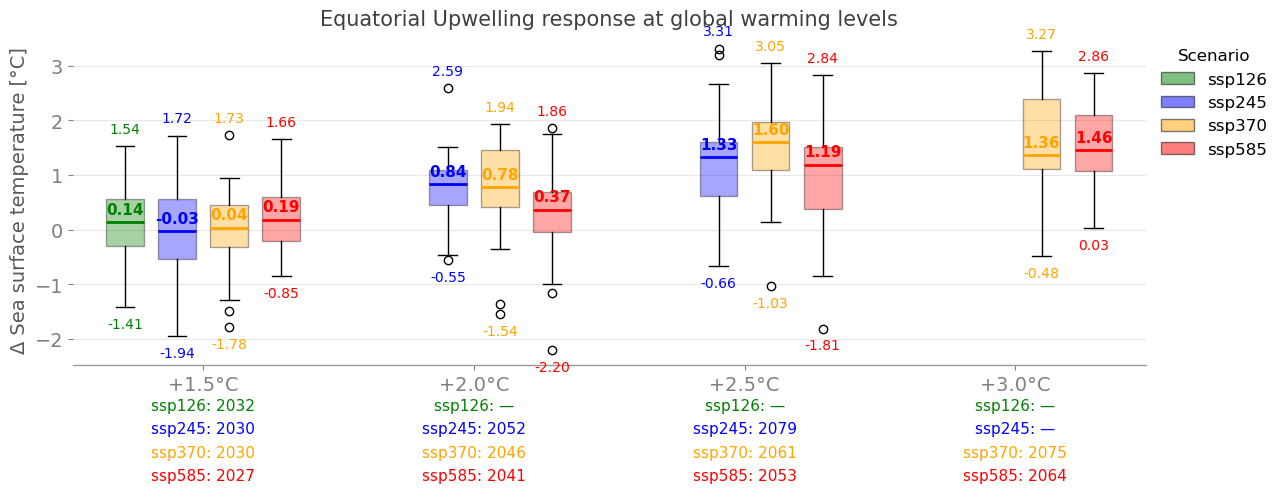

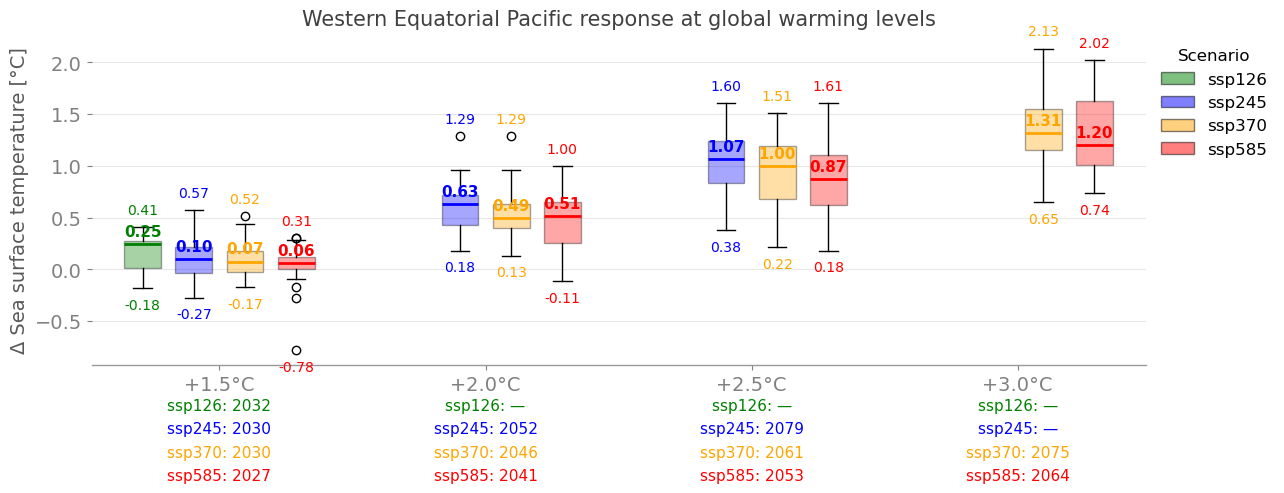

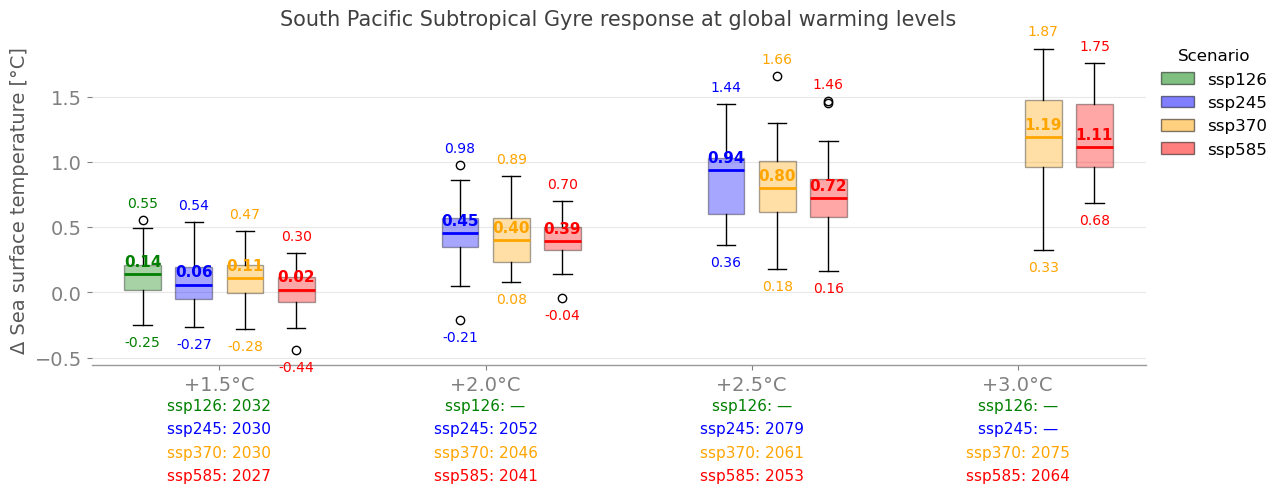

In [4]:
ds = reg.extract_regional_means("tos", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tos", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
glue("tos_fig", figs["levels"], display=False)
tables["regions"]